# Bank marketing

Inspect the UCI Bank Marketing dataset (id 222). Each row is one client of a Portuguese bank who was phoned during a direct marketing campaign. The features describe the client (age, job, balance, loans) and the contact (channel, month, call duration, earlier campaigns). `y` is whether the client subscribed to a term deposit.

A logistic regression is the baseline. Later experiments change one thing at a time.

## Trust the dataset download

`ucimlrepo` checks the UCI server with the `certifi` certificate bundle. On this machine Avast Web/Mail Shield scans HTTPS, so the server certificate is issued by Avast's local root. Windows already trusts that root, and `certifi` does not. The next cell keeps certificate checks on and uses the Windows trust store for this session so the download can succeed.

In [1]:
import ssl

_create_default_context = ssl.create_default_context


def _create_default_context_windows_store(*args, **kwargs):
    '''Use the OS trust store, which includes the Avast scanning root.'''
    return _create_default_context()


ssl.create_default_context = _create_default_context_windows_store

## Load the dataset

In [2]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)

df = X.rename(columns={"day_of_week": "day"})
df["y"] = y.iloc[:, 0]

print(df.shape)
print(list(df.columns))

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

## Keeping the call duration

`duration` is the length of the call in seconds. It is only known once the call is under way, so it cannot decide whom to call in the first place. It is kept on purpose, to answer a different question: once a client is on the phone, is it worth insisting? A client who stays on the line is usually listening, so a long call is a sign the bank should keep trying. The scores below say how well the outcome can be told while the call is running, not before it. A long call does not create a subscriber, so the signal shows who is worth the effort, not that calls should be stretched.

## Inspect the data

`df` is 45,211 clients: 16 features plus the target `y`. Seven columns are numbers and the rest are text categories. Four columns have missing values: `poutcome` (36,959, the outcome of a previous campaign, missing for clients never contacted before), `contact` (13,020), `education` (1,857), and `job` (288).

The source names a column `day_of_week`, but it is a number from 1 to 31: the day of the month the client was called, not a weekday. It is renamed `day`. `pdays` is -1 for clients not contacted before.

In [3]:
print(df.head())
df.info()
print(df.describe())
print(df.isnull().sum())

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day month  duration  campaign  pdays  previous poutcome   y  
0     NaN    5   may       261         1     -1         0      NaN  no  
1     NaN    5   may       151         1     -1         0      NaN  no  
2     NaN    5   may        76         1     -1         0      NaN  no  
3     NaN    5   may        92         1     -1         0      NaN  no  
4     NaN    5   may       198         1     -1         0      NaN  no  
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non

## Investigate the target

`y` is `no` for 39,922 clients (88.3%) and `yes` for 5,289 clients (11.7%). The classes are strongly imbalanced, so accuracy alone will be misleading later: always answering `no` would already be right 88% of the time.

In [4]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


### Correlations

Text columns are turned into numbers (missing values become their own category first) and `y` becomes 0 or 1, so every column can enter a correlation with the target.

In [5]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

encoded = df.copy()
for col in encoded.select_dtypes(exclude="number").columns:
    encoded[col] = encoded[col].fillna("missing").astype("category").cat.codes
encoded["y"] = (df["y"] == "yes").astype(int)

corr = encoded.corr()
print(corr["y"].drop("y").sort_values(key=abs, ascending=False).round(3))

duration     0.395
poutcome     0.213
housing     -0.139
pdays        0.104
contact     -0.101
previous     0.093
campaign    -0.073
loan        -0.068
balance      0.053
education    0.051
marital      0.046
job          0.042
day         -0.028
age          0.025
month       -0.024
default     -0.022
Name: y, dtype: float64


Call `duration` is by far the strongest correlate of `y` (0.39), followed by `poutcome` (0.21), `housing` (-0.14), `pdays` (0.10), and `contact` (-0.10). Clients with a home loan subscribe less. Everything else is below 0.1 in absolute value.

The correlations of the text columns are only rough. Their numbers are alphabetical codes with no real order, and a correlation measures a straight-line relationship, so a weak value does not mean a column is useless.

## Visualise relationships

The pairplot crosses age, account balance, call duration, and number of contacts in this campaign (`campaign`), colored by `y`. It uses a random sample of 2,000 clients so the plot stays readable and fast. Call duration is the clearest signal: clients who subscribed tend to have had longer calls. Balance and `campaign` have long right tails, so most points are packed near the low end.

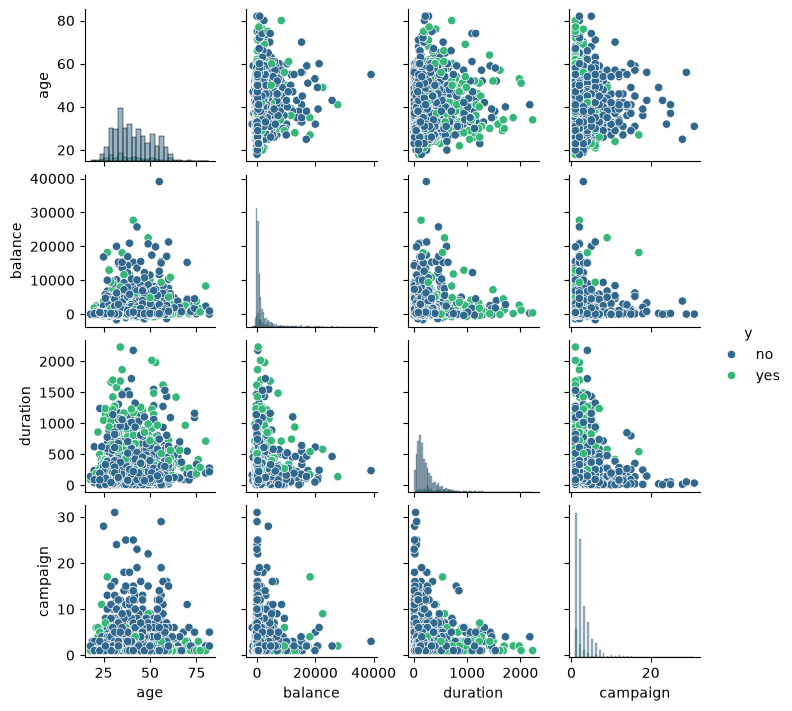

In [6]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = df[["age", "balance", "duration", "campaign", "y"]].sample(2000, random_state=42)

sns.pairplot(plot_df, hue="y", diag_kind="hist", height=1.8, palette="viridis")
plt.show()

## Train and test split

Hold out 20% of the clients and stratify on `y`, so the 12% of subscribers is the same in both sets.

The split gives 36,168 training rows and 9,043 test rows. Subscribers are 11.70% of both sets.

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="y")
y = (df["y"] == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(36168, 16) (9043, 16)
0.11698186241981863 0.11699657193409267


## Baseline

A logistic regression inside a pipeline, kept as plain as possible. Text columns are turned into numbers with an ordinal encoder, and their missing values become their own category `missing` first. Every column is then scaled. The numbers given to the categories are arbitrary (alphabetical), so this is a crude encoding that later experiments can improve. All 16 features are used, including `duration`.

Accuracy is reported, but because only 12% of clients subscribed, precision, recall, and ROC AUC are reported too.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

categorical = X.select_dtypes(exclude="number").columns

encode = ColumnTransformer([
    (
        "cat",
        make_pipeline(
            SimpleImputer(strategy="constant", fill_value="missing"),
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        ),
        categorical,
    ),
], remainder="passthrough")

baseline = make_pipeline(encode, StandardScaler(), LogisticRegression(max_iter=10000))
baseline.fit(X_train, y_train)

pred = baseline.predict(X_test)
proba = baseline.predict_proba(X_test)[:, 1]
print("accuracy:", accuracy_score(y_test, pred))
print("roc auc:", roc_auc_score(y_test, proba))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["no", "yes"]))

accuracy: 0.8979321021784806
roc auc: 0.8733957692412403
[[7818  167]
 [ 756  302]]
              precision    recall  f1-score   support

          no       0.91      0.98      0.94      7985
         yes       0.64      0.29      0.40      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.63      0.67      9043
weighted avg       0.88      0.90      0.88      9043



The baseline scores 0.898 accuracy on the 9,043 held-out clients, only 1.5 points above always answering `no` (88.3%). ROC AUC is 0.873, so the model still ranks subscribers above non-subscribers fairly well.

The confusion matrix shows where the accuracy comes from. Of 7,985 clients who said no, 7,818 are right. Of 1,058 who said yes, only 302 are found (recall 0.29), and 756 are missed. When the model predicts yes it is right 64% of the time.

The F1 score for `yes` is poor (0.40), but that is understandable. There are about nine times more `no` than `yes`, so the model gets most of its reward by leaning toward `no`. The default 0.5 threshold is cautious for a rare class, and a plain logistic regression has no reason to push harder on the minority. F1 for `no` is 0.94 for the same reason. Recall on `yes` is the number to improve in the experiments.

## One change at a time

Every experiment below changes one thing from the one before it and is scored on the same held-out rows. The helper keeps each result so they can be compared at the end.

In [9]:
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

results = {}


def record(name, y_true, pred, proba):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, pred, pos_label=1, average="binary"
    )
    results[name] = {
        "accuracy": accuracy_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba),
        "precision_yes": precision,
        "recall_yes": recall,
        "f1_yes": f1,
    }


def report(name, model, X_tr, X_te, y_tr=None):
    model.fit(X_tr, y_train if y_tr is None else y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    record(name, y_test, pred, proba)
    print(name)
    print(pd.Series(results[name]).round(3).to_string())
    print(confusion_matrix(y_test, pred))


record("baseline: logreg, ordinal", y_test, pred, proba)

### One-hot encoding

The three binary columns (`default`, `housing`, `loan`) stay as 0 and 1. The other text columns (`job`, `marital`, `education`, `contact`, `month`, `poutcome`) get one column per category, so the model no longer treats the alphabetical codes as an order. Missing values are still their own category. The model is the same logistic regression.

In [10]:
from sklearn.preprocessing import FunctionTransformer, KBinsDiscretizer, OneHotEncoder

binary = ["default", "housing", "loan"]
multi = ["job", "marital", "education", "contact", "month", "poutcome"]


def pdays_group(columns):
    days = columns.iloc[:, 0]
    group = pd.cut(
        days,
        [-2, -0.5, 90, 180, 365, np.inf],
        labels=["never", "1-90", "91-180", "181-365", "over 365"],
    )
    return group.astype(str).to_frame()


def make_encoder(multi_columns, bins=None, pdays=False):
    steps = [
        ("binary", OrdinalEncoder(), binary),
        (
            "multi",
            make_pipeline(
                SimpleImputer(strategy="constant", fill_value="missing"),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            multi_columns,
        ),
    ]
    for column, n_bins in (bins or {}).items():
        steps.append((
            f"bin_{column}",
            KBinsDiscretizer(n_bins=n_bins, encode="onehot-dense", strategy="quantile"),
            [column],
        ))
    if pdays:
        steps.append((
            "pdays",
            make_pipeline(
                FunctionTransformer(pdays_group),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            ["pdays"],
        ))
    return ColumnTransformer(steps, remainder="passthrough")


report(
    "logreg, one-hot",
    make_pipeline(make_encoder(multi), StandardScaler(), LogisticRegression(max_iter=10000)),
    X_train,
    X_test,
)

logreg, one-hot
accuracy         0.901
roc_auc          0.905
precision_yes    0.645
recall_yes       0.349
f1_yes           0.453
[[7782  203]
 [ 689  369]]


One-hot encoding helps even though accuracy barely moves (0.898 to 0.901). ROC AUC goes from 0.873 to 0.905, recall on `yes` from 0.285 to 0.349, and F1 from 0.396 to 0.453. The alphabetical codes were forcing a straight-line order on columns like `month`, `job`, and `poutcome`, and one column per category lets each one carry its own weight.

### Gradient boosting

Same one-hot encoding, a different model. Gradient boosting builds many small trees one after another, and each new tree is fit to the mistakes of the ones before it. Scaling is dropped because trees only compare each column to a threshold. The settings are scikit-learn's defaults (100 trees of depth 3).

In [11]:
from sklearn.ensemble import GradientBoostingClassifier

report(
    "gradient boosting, one-hot",
    make_pipeline(make_encoder(multi), GradientBoostingClassifier(random_state=42)),
    X_train,
    X_test,
)

gradient boosting, one-hot
accuracy         0.905
roc_auc          0.924
precision_yes    0.653
recall_yes       0.410
f1_yes           0.504
[[7754  231]
 [ 624  434]]


Gradient boosting beats the logistic regression: accuracy 0.905, ROC AUC 0.924 (up from 0.905), recall on `yes` 0.410 (434 of 1,058 found, up from 0.349), and F1 0.504 (up from 0.453). Each new tree is fit to the mistakes of the previous ones, so the model can pick up combinations of columns that a straight-line model cannot. Precision is 0.653, about the same as before.

### Random forest

Same encoding again, with a forest of trees that each see a bootstrap sample and a random subset of columns.

In [12]:
from sklearn.ensemble import RandomForestClassifier

report(
    "random forest, one-hot",
    make_pipeline(make_encoder(multi), RandomForestClassifier(random_state=42, n_jobs=-1)),
    X_train,
    X_test,
)

random forest, one-hot
accuracy         0.908
roc_auc          0.924
precision_yes    0.683
recall_yes       0.401
f1_yes           0.505
[[7788  197]
 [ 634  424]]


The forest is about level with gradient boosting: accuracy 0.908, ROC AUC 0.924 (the same), precision 0.683, recall 0.401, and F1 0.505 (against 0.504). It averages many deep trees that each see a bootstrap sample, while boosting stacks shallow ones. The gaps between the two are a handful of clients out of 9,043, so neither is clearly better. Both beat the logistic regression, so a model that is not a straight line helps here. Recall on `yes` is still around 0.4, so both miss most of the subscribers at the default threshold.

### The real day of the week

`day` is the day of the month, which says little by itself. The rows are in the order the calls were made: the months run May to December, then January to December, then January to November, and the day numbers rise inside each month. The data documentation gives the span as May 2008 to November 2010, so every time the month number drops from one row to the next, a new year has started. With a year, month, and day, the calendar gives the weekday of each call.

As a check, a bank call center should not be calling on weekends.

In [13]:
month_number = df["month"].map(
    {m: i for i, m in enumerate(
        ["jan", "feb", "mar", "apr", "may", "jun",
         "jul", "aug", "sep", "oct", "nov", "dec"], start=1)}
)
year = 2008 + (month_number < month_number.shift(fill_value=month_number.iloc[0])).cumsum()

call_date = pd.to_datetime(
    pd.DataFrame({"year": year, "month": month_number, "day": df["day"]})
)
weekday = call_date.dt.day_name().rename("weekday")

print(call_date.min(), call_date.max())
print(year.value_counts().sort_index())
print(weekday.value_counts())

2008-05-05 00:00:00 2010-11-17 00:00:00
month
2008    27729
2009    14862
2010     2620
Name: count, dtype: int64
weekday
Thursday     9754
Monday       9522
Wednesday    8914
Friday       8707
Tuesday      8264
Saturday       30
Sunday         20
Name: count, dtype: int64


The dates run from 5 May 2008 to 17 November 2010, with 27,729 calls in 2008, 14,862 in 2009, and 2,620 in 2010. The check holds: only 50 of 45,211 calls (30 on Saturday and 20 on Sunday) fall on a weekend, and the rest are spread across Monday to Friday. That is strong evidence that the reconstructed years are right, so the weekday is real and not a guess.

### Weekday as a feature

The weekday joins the one-hot columns, and the three models are fit again on the same rows.

In [14]:
X_train_w = X_train.assign(weekday=weekday.loc[X_train.index])
X_test_w = X_test.assign(weekday=weekday.loc[X_test.index])
multi_w = multi + ["weekday"]

report(
    "logreg, one-hot + weekday",
    make_pipeline(make_encoder(multi_w), StandardScaler(), LogisticRegression(max_iter=10000)),
    X_train_w,
    X_test_w,
)
report(
    "gradient boosting, one-hot + weekday",
    make_pipeline(make_encoder(multi_w), GradientBoostingClassifier(random_state=42)),
    X_train_w,
    X_test_w,
)
report(
    "random forest, one-hot + weekday",
    make_pipeline(make_encoder(multi_w), RandomForestClassifier(random_state=42, n_jobs=-1)),
    X_train_w,
    X_test_w,
)

logreg, one-hot + weekday
accuracy         0.902
roc_auc          0.905
precision_yes    0.653
recall_yes       0.353
f1_yes           0.459
[[7786  199]
 [ 684  374]]


gradient boosting, one-hot + weekday
accuracy         0.906
roc_auc          0.924
precision_yes    0.657
recall_yes       0.407
f1_yes           0.503
[[7760  225]
 [ 627  431]]


random forest, one-hot + weekday
accuracy         0.907
roc_auc          0.929
precision_yes    0.679
recall_yes       0.385
f1_yes           0.491
[[7793  192]
 [ 651  407]]


The weekday changes very little. Logistic regression gains a hair (F1 0.453 to 0.459). Gradient boosting does not move (F1 0.504 to 0.503, AUC 0.924 both times). The forest's AUC rises from 0.924 to 0.929, but its recall and F1 fall (0.401 to 0.385 and 0.505 to 0.491). With 1,058 subscribers in the test set, a few rows decide differences this size, so these are not reliable gains or losses. Whether a call falls on a Monday or a Thursday tells the models almost nothing about who subscribes.

### Binning numbers (no luck)

One more idea: cut `balance` (10 bins), `age` (8 bins), and `pdays` (never contacted, then four ranges of days) into categories, added one after the other on the one-hot logistic regression. Then the same bins go to the forest and gradient boosting. None of it helped: the logistic regression stays at F1 0.453 through all three, and the tree models get slightly worse, since trees already pick their own cut points. These three signals are weak or already covered by `poutcome` and `previous`.

In [15]:
def logreg_with(bins=None, pdays=False):
    return make_pipeline(
        make_encoder(multi, bins=bins, pdays=pdays),
        StandardScaler(),
        LogisticRegression(max_iter=10000),
    )


all_bins = {"balance": 10, "age": 8}

report("logreg, + balance bins", logreg_with({"balance": 10}), X_train, X_test)
report("logreg, + age bins", logreg_with(all_bins), X_train, X_test)
report("logreg, + pdays groups", logreg_with(all_bins, pdays=True), X_train, X_test)
report(
    "gradient boosting, + all bins",
    make_pipeline(make_encoder(multi, bins=all_bins, pdays=True), GradientBoostingClassifier(random_state=42)),
    X_train,
    X_test,
)
report(
    "random forest, + all bins",
    make_pipeline(make_encoder(multi, bins=all_bins, pdays=True), RandomForestClassifier(random_state=42, n_jobs=-1)),
    X_train,
    X_test,
)

logreg, + balance bins
accuracy         0.901
roc_auc          0.905
precision_yes    0.645
recall_yes       0.349
f1_yes           0.453
[[7782  203]
 [ 689  369]]


logreg, + age bins
accuracy         0.901
roc_auc          0.906
precision_yes    0.639
recall_yes       0.351
f1_yes           0.453
[[7775  210]
 [ 687  371]]


logreg, + pdays groups
accuracy         0.901
roc_auc          0.907
precision_yes    0.645
recall_yes       0.350
f1_yes           0.453
[[7781  204]
 [ 688  370]]


gradient boosting, + all bins
accuracy         0.906
roc_auc          0.923
precision_yes    0.662
recall_yes       0.397
f1_yes           0.496
[[7771  214]
 [ 638  420]]


random forest, + all bins
accuracy         0.904
roc_auc          0.924
precision_yes    0.662
recall_yes       0.370
f1_yes           0.474
[[7785  200]
 [ 667  391]]


### All results

In [16]:
print(pd.DataFrame(results).T.round(3))

                                      accuracy  roc_auc  precision_yes  recall_yes  f1_yes
baseline: logreg, ordinal                0.898    0.873          0.644       0.285   0.396
logreg, one-hot                          0.901    0.905          0.645       0.349   0.453
gradient boosting, one-hot               0.905    0.924          0.653       0.410   0.504
random forest, one-hot                   0.908    0.924          0.683       0.401   0.505
logreg, one-hot + weekday                0.902    0.905          0.653       0.353   0.459
gradient boosting, one-hot + weekday     0.906    0.924          0.657       0.407   0.503
random forest, one-hot + weekday         0.907    0.929          0.679       0.385   0.491
logreg, + balance bins                   0.901    0.905          0.645       0.349   0.453
logreg, + age bins                       0.901    0.906          0.639       0.351   0.453
logreg, + pdays groups                   0.901    0.907          0.645       0.350   0.453

### Which model

Gradient boosting and the random forest are the best models, and they are tied: F1 on `yes` is 0.504 and 0.505, and ROC AUC is 0.924 for both. If the target is a good overall hit rate or a well-ranked list of clients, gradient boosting would be the one to use. It stayed steady through the weekday and binning changes, and it finds slightly more subscribers. The forest is just as defensible if precision matters more (0.683 against 0.653). One-hot encoding was the only change that helped. The weekday and the binning did not.

But every model finds only about 40% of the subscribers (recall on `yes` is 0.41 at best). About 88% of the rows are `no`, so the models lean toward `no`. If the target is instead to catch as many subscribers as possible, and a wasted call is cheap, we could even out the training data. That is tried next on the five best models in the table above, ranked by F1 on `yes`. Every model here uses `duration`, so these scores answer whether insisting on a call is worth the try, not whom to call.

### Evening out the training data

For each of the five models, the `no` clients in the training set are randomly cut down to the same number as the `yes` clients (4,231 of each, 8,462 rows). The test set is left alone, so it keeps the real 12% of subscribers and the scores stay comparable.

In [17]:
rng = np.random.RandomState(42)
yes_index = y_train[y_train == 1].index
no_index = pd.Index(rng.choice(y_train[y_train == 0].index, size=len(yes_index), replace=False))
even_index = yes_index.append(no_index)
y_even = y_train.loc[even_index]
print(len(even_index), y_even.mean())

gb = lambda enc: make_pipeline(enc, GradientBoostingClassifier(random_state=42))
rf = lambda enc: make_pipeline(enc, RandomForestClassifier(random_state=42, n_jobs=-1))

builders = {
    "gradient boosting, one-hot": (gb(make_encoder(multi)), X_train, X_test),
    "random forest, one-hot": (rf(make_encoder(multi)), X_train, X_test),
    "gradient boosting, one-hot + weekday": (gb(make_encoder(multi_w)), X_train_w, X_test_w),
    "random forest, one-hot + weekday": (rf(make_encoder(multi_w)), X_train_w, X_test_w),
    "gradient boosting, + all bins": (gb(make_encoder(multi, bins=all_bins, pdays=True)), X_train, X_test),
    "random forest, + all bins": (rf(make_encoder(multi, bins=all_bins, pdays=True)), X_train, X_test),
}

top5 = pd.DataFrame(results).T.sort_values("f1_yes", ascending=False).head(5).index.tolist()
print(top5)

for name in top5:
    model, X_tr, X_te = builders[name]
    report(name + " [even]", model, X_tr.loc[even_index], X_te, y_even)

8462 0.5
['random forest, one-hot', 'gradient boosting, one-hot', 'gradient boosting, one-hot + weekday', 'gradient boosting, + all bins', 'random forest, one-hot + weekday']


random forest, one-hot [even]
accuracy         0.836
roc_auc          0.926
precision_yes    0.408
recall_yes       0.889
f1_yes           0.559
[[6619 1366]
 [ 117  941]]


gradient boosting, one-hot [even]
accuracy         0.839
roc_auc          0.922
precision_yes    0.412
recall_yes       0.872
f1_yes           0.559
[[6665 1320]
 [ 135  923]]


gradient boosting, one-hot + weekday [even]
accuracy         0.839
roc_auc          0.922
precision_yes    0.412
recall_yes       0.873
f1_yes           0.560
[[6667 1318]
 [ 134  924]]


gradient boosting, + all bins [even]
accuracy         0.839
roc_auc          0.922
precision_yes    0.412
recall_yes       0.871
f1_yes           0.559
[[6669 1316]
 [ 136  922]]


random forest, one-hot + weekday [even]
accuracy         0.838
roc_auc          0.928
precision_yes    0.411
recall_yes       0.892
f1_yes           0.563
[[6632 1353]
 [ 114  944]]


Evening out the data does what a lower threshold would do. For all five models, recall on `yes` jumps from about 0.4 to 0.87–0.89 (the forest finds 941 of the 1,058 subscribers, against 424 before). Precision falls from 0.65–0.68 to about 0.41, accuracy from 0.905 to 0.838, and the number of wrongly flagged clients rises from about 200 to 1,300–1,370. F1 on `yes` rises from about 0.50 to about 0.56, and ROC AUC does not move (0.922 to 0.928), which confirms the models rank clients just as well as before and only say `yes` more readily.

The five models end up almost the same (F1 0.559 to 0.563), so the weekday and the bins still make no difference. In practice, the forest flags 2,307 of the 9,043 clients, about a quarter of them, and reaches 89% of the subscribers. Without a model, reaching them all would mean calling all 9,043. So if a wasted call is cheap compared with a missed subscriber, the evened-out model is the one to use. If calls are costly, the original gradient boosting or forest is better.

In [18]:
even = [name + " [even]" for name in top5]
print(pd.DataFrame(results).T.loc[top5 + even].round(3))

                                             accuracy  roc_auc  precision_yes  recall_yes  f1_yes
random forest, one-hot                          0.908    0.924          0.683       0.401   0.505
gradient boosting, one-hot                      0.905    0.924          0.653       0.410   0.504
gradient boosting, one-hot + weekday            0.906    0.924          0.657       0.407   0.503
gradient boosting, + all bins                   0.906    0.923          0.662       0.397   0.496
random forest, one-hot + weekday                0.907    0.929          0.679       0.385   0.491
random forest, one-hot [even]                   0.836    0.926          0.408       0.889   0.559
gradient boosting, one-hot [even]               0.839    0.922          0.412       0.872   0.559
gradient boosting, one-hot + weekday [even]     0.839    0.922          0.412       0.873   0.560
gradient boosting, + all bins [even]            0.839    0.922          0.412       0.871   0.559
random forest, one-h

## Conclusion

The table has 45,211 clients with 16 features, and 11.7% of them subscribed to a term deposit. The stratified 80/20 split gave 36,168 training rows and 9,043 test rows, with the same 11.7% in both.

The baseline, a logistic regression with alphabetical category codes, scored 0.898 accuracy and 0.873 ROC AUC, but found only 28.5% of the subscribers (F1 0.396). One-hot encoding the categories raised it to 0.901, 0.905, 34.9% recall, and F1 0.453. Gradient boosting (0.905, 0.924, recall 0.410, F1 0.504) and the random forest (0.908, 0.924, recall 0.401, F1 0.505) were then tied for best.

The real weekday of each call, rebuilt from the row order (5 May 2008 to 17 November 2010), changed the scores by only a few clients. Binning `balance`, `age`, and `pdays` left the logistic regression at F1 0.453 and made the tree models slightly worse (gradient boosting 0.496, forest 0.474). Neither idea is worth keeping.

Evening out the training data on the five best models raised recall on `yes` to 0.87 to 0.89 and F1 to 0.56, at the cost of precision (about 0.41) and accuracy (0.838). ROC AUC did not change, so this moves the threshold and does not improve the ranking. With calls that are cheap, that is the model to use. Otherwise gradient boosting or the forest on the original data is the better choice. `duration` was kept on purpose, to judge whether insisting on a call is worth the try. It is the strongest signal by far (correlation 0.39 with the target), but it is only known once the call is under way, so it says who is worth staying on the line with, not whom to call.